# 02. Modelado y evaluación con riesgos competitivos

Este notebook ajusta y evalúa tres modelos supervisados de tiempo hasta el evento:

1. **Cox de causa específica** (se ajusta un modelo para fallecimiento y otro para trasplante para reconstruir la incidencia acumulada de fallecimiento).
2. **Fine-Gray**, para el riesgo de subdistribución del fallecimiento.
3. **Bosque de supervivencia para riesgos competitivos**, basado en árboles y capaz de producir incidencias acumuladas para ambos eventos.

El estimador de Aalen-Johansen se utiliza como referencia descriptiva. No se usan redes neuronales.

**Codificación obligatoria:** 0 = censura (`C`); 1 = fallecimiento (`D`); 2 = trasplante (`CL`). El trasplante se modela como evento competitivo, no como fallecimiento ni como supervivencia indefinida.

Se utiliza validación cruzada estratificada de cinco pliegues y predicciones fuera de pliegue (OOF). Las métricas principales serán AUC dependiente del tiempo, Brier score, AUC integrada, Brier integrado, calibración y concordancia por causa. No se incorporan valores de resultados hasta ejecutar el notebook.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from importlib.metadata import version

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Abra Jupyter desde la carpeta raíz Proyecto_Cirrosis_Supervivencia.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cirrhosis_data import load_cirrhosis_data
from src.survival_models import run_competing_risk_analysis

print("comprisk instalado:", version("comprisk"))
print("Se recomienda usar la versión fijada en requirements.txt (0.8.0).")
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"


comprisk instalado: 0.8.0
Se recomienda usar la versión fijada en requirements.txt (0.8.0).


## 1. Carga y controles previos

In [2]:
df = load_cirrhosis_data()
print("Dimensiones:", df.shape)
print("Distribución de Status:")
display(df["Status_label"].value_counts().rename_axis("Status").to_frame("n"))
print("Variables candidatas:")
print(["Age_years", "log_Bilirubin", "log_Albumin", "log_Prothrombin", "Edema_score"])
print("Horizontes predefinidos: 1, 2 y 3 años (365.25, 730.5 y 1,095.75 días).")

Dimensiones: (418, 21)
Distribución de Status:


,n
Status,
C,232
D,161
CL,25


Variables candidatas:
['Age_years', 'log_Bilirubin', 'log_Albumin', 'log_Prothrombin', 'Edema_score']
Horizontes predefinidos: 1, 2 y 3 años (365.25, 730.5 y 1,095.75 días).


## 2. Ejecutar validación cruzada y entrenar modelos

In [3]:
results = run_competing_risk_analysis(
    df=df,
    output_dir=ROOT / "results",
    n_splits=5,
    eval_times=(365.25, 730.5, 1095.75),
    n_estimators=300,
    n_bootstrap=200,
    random_state=42,
    n_jobs=1,
)
print("Análisis finalizado. Las tablas y figuras quedaron guardadas en results/.")

Pliegue 1/5 finalizado.
Pliegue 2/5 finalizado.
Pliegue 3/5 finalizado.
Pliegue 4/5 finalizado.
Pliegue 5/5 finalizado.
Análisis finalizado. Las tablas y figuras quedaron guardadas en results/.


## 3. Resultados de AUC dependiente del tiempo

In [4]:
display(results["auc"])
print("AUC integrada (iAUC):")
display(results["iauc"])

,model,times,AUC,lower,upper
0,Cox causa-específica,365.25,0.879124,0.791495,0.932155
1,Cox causa-específica,730.50,0.848083,0.791789,0.903179
2,Cox causa-específica,1095.75,0.882172,0.842849,0.919292
3,Fine-Gray,365.25,0.880412,0.792798,0.934762
4,Fine-Gray,730.50,0.852716,0.796970,0.908574
5,Fine-Gray,1095.75,0.882322,0.845510,0.918562
6,Bosque supervivencia riesgos competitivos,365.25,0.885567,0.798164,0.944674
7,Bosque supervivencia riesgos competitivos,730.50,0.853372,0.795369,0.918312
8,Bosque supervivencia riesgos competitivos,1095.75,0.870020,0.826499,0.905575


AUC integrada (iAUC):


,model,iAUC,lower,upper
0,Cox causa-específica,0.864366,0.810265,0.912210
1,Fine-Gray,0.867042,0.815072,0.915414
2,Bosque supervivencia riesgos competitivos,0.865583,0.808675,0.917512


## 4. Resultados de Brier score

In [5]:
display(results["brier"])
print("Brier integrado (IBS):")
display(results["ibs"])

,model,times,Brier,lower,upper
0,Cox causa-específica,365.25,0.048293,0.034677,0.063185
1,Cox causa-específica,730.50,0.077035,0.061881,0.093571
2,Cox causa-específica,1095.75,0.102581,0.089006,0.120624
3,Fine-Gray,365.25,0.047690,0.034532,0.062635
4,Fine-Gray,730.50,0.075539,0.060239,0.091996
5,Fine-Gray,1095.75,0.101750,0.088143,0.118814
6,Bosque supervivencia riesgos competitivos,365.25,0.048354,0.036719,0.061224
7,Bosque supervivencia riesgos competitivos,730.50,0.073125,0.059035,0.090288
8,Bosque supervivencia riesgos competitivos,1095.75,0.102746,0.086192,0.120615


Brier integrado (IBS):


,model,IBS,lower,upper
0,Cox causa-específica,0.076236,0.063527,0.091434
1,Fine-Gray,0.075130,0.062569,0.089544
2,Bosque supervivencia riesgos competitivos,0.074337,0.062482,0.089122


## 5. Concordancia por causa

In [6]:
display(results["concordance"])
print("Interpretación: valores más altos indican mejor ordenamiento de riesgo; revisar intervalos y limitaciones de muestra.")

,modelo,c_index_uno,limite_inferior_95,limite_superior_95,nota
0,Cox causa-específica,0.784259,0.742195,0.821114,Concordancia por causa en predicciones fuera d...
1,Fine-Gray,0.788213,0.746284,0.824839,Concordancia por causa en predicciones fuera d...
2,Bosque supervivencia riesgos competitivos,0.772034,0.728830,0.810147,Concordancia por causa en predicciones fuera d...


Interpretación: valores más altos indican mejor ordenamiento de riesgo; revisar intervalos y limitaciones de muestra.


## 6. Coeficientes y convergencia de Cox

In [7]:
display(results["coefficients"].head(20))
print("Diagnóstico de convergencia:")
display(results["convergence"])
print("Los coeficientes corresponden a variables estandarizadas en cada pliegue. La exponencial del coeficiente es una razón de riesgo asociada al cambio de una desviación estándar en esa transformación, no una relación causal.")

,pliegue,modelo,variable,coeficiente_escala_estandarizada,razon_riesgo_exponencial,tipo_efecto
0,1,Cox causa-específica: fallecimiento,Age_years,0.377333,1.458389,HR causa-específica
1,1,Cox causa-específica: fallecimiento,log_Bilirubin,0.806101,2.239161,HR causa-específica
2,1,Cox causa-específica: fallecimiento,log_Albumin,-0.316960,0.728360,HR causa-específica
3,1,Cox causa-específica: fallecimiento,log_Prothrombin,0.215906,1.240986,HR causa-específica
4,1,Cox causa-específica: fallecimiento,Edema_score,0.204357,1.226735,HR causa-específica
5,1,Cox causa-específica: trasplante,Age_years,-0.918554,0.399096,HR causa-específica
6,1,Cox causa-específica: trasplante,log_Bilirubin,0.844418,2.326623,HR causa-específica
7,1,Cox causa-específica: trasplante,log_Albumin,-0.483685,0.616507,HR causa-específica
8,1,Cox causa-específica: trasplante,log_Prothrombin,-0.699803,0.496683,HR causa-específica
9,1,Cox causa-específica: trasplante,Edema_score,-0.286656,0.750770,HR causa-específica


Diagnóstico de convergencia:


,pliegue,modelo,convergio,iteraciones
0,1,Cox causa-específica: fallecimiento,True,5
1,1,Cox causa-específica: trasplante,True,5
2,1,Fine-Gray: fallecimiento,True,4
3,2,Cox causa-específica: fallecimiento,True,5
4,2,Cox causa-específica: trasplante,True,4
5,2,Fine-Gray: fallecimiento,True,4
6,3,Cox causa-específica: fallecimiento,True,5
7,3,Cox causa-específica: trasplante,True,5
8,3,Fine-Gray: fallecimiento,True,4
9,4,Cox causa-específica: fallecimiento,True,5


Los coeficientes corresponden a variables estandarizadas en cada pliegue. La exponencial del coeficiente es una razón de riesgo asociada al cambio de una desviación estándar en esa transformación, no una relación causal.


## 7. Calibración y comparación gráfica

,model,times,predicted_decile,observed_freq,lower_ci,upper_ci,bin_n
0,Cox causa-específica,1095.75,0.026445,0.023810,0.006554,0.082714,84
1,Cox causa-específica,1095.75,0.051752,0.024245,0.006698,0.083883,83
2,Cox causa-específica,1095.75,0.089518,0.047772,0.018758,0.116338,84
3,Cox causa-específica,1095.75,0.198976,0.279729,0.194565,0.384381,83
4,Cox causa-específica,1095.75,0.617021,0.607143,0.500218,0.704697,84
5,Fine-Gray,1095.75,0.027706,0.023810,0.006554,0.082714,84
6,Fine-Gray,1095.75,0.054246,0.024096,0.006633,0.083663,83
7,Fine-Gray,1095.75,0.091985,0.036316,0.012529,0.100658,84
8,Fine-Gray,1095.75,0.201431,0.290144,0.203527,0.395328,83
9,Fine-Gray,1095.75,0.621675,0.607143,0.500218,0.704697,84


Figuras disponibles:
- 01_incidencia_acumulada_aj.png
- 02_cif_observada_vs_predicha.png
- 03_auc_dependiente_tiempo.png
- 04_brier_dependiente_tiempo.png
- 05_importancia_variables_bosque.png
- 06_calibracion_cif_horizonte_final.png
- eda_01_distribucion_status.png
- eda_02_valores_faltantes.png
- eda_distribucion_age_years_eda.png
- eda_distribucion_albumin.png
- eda_distribucion_bilirubin.png
- eda_distribucion_prothrombin.png


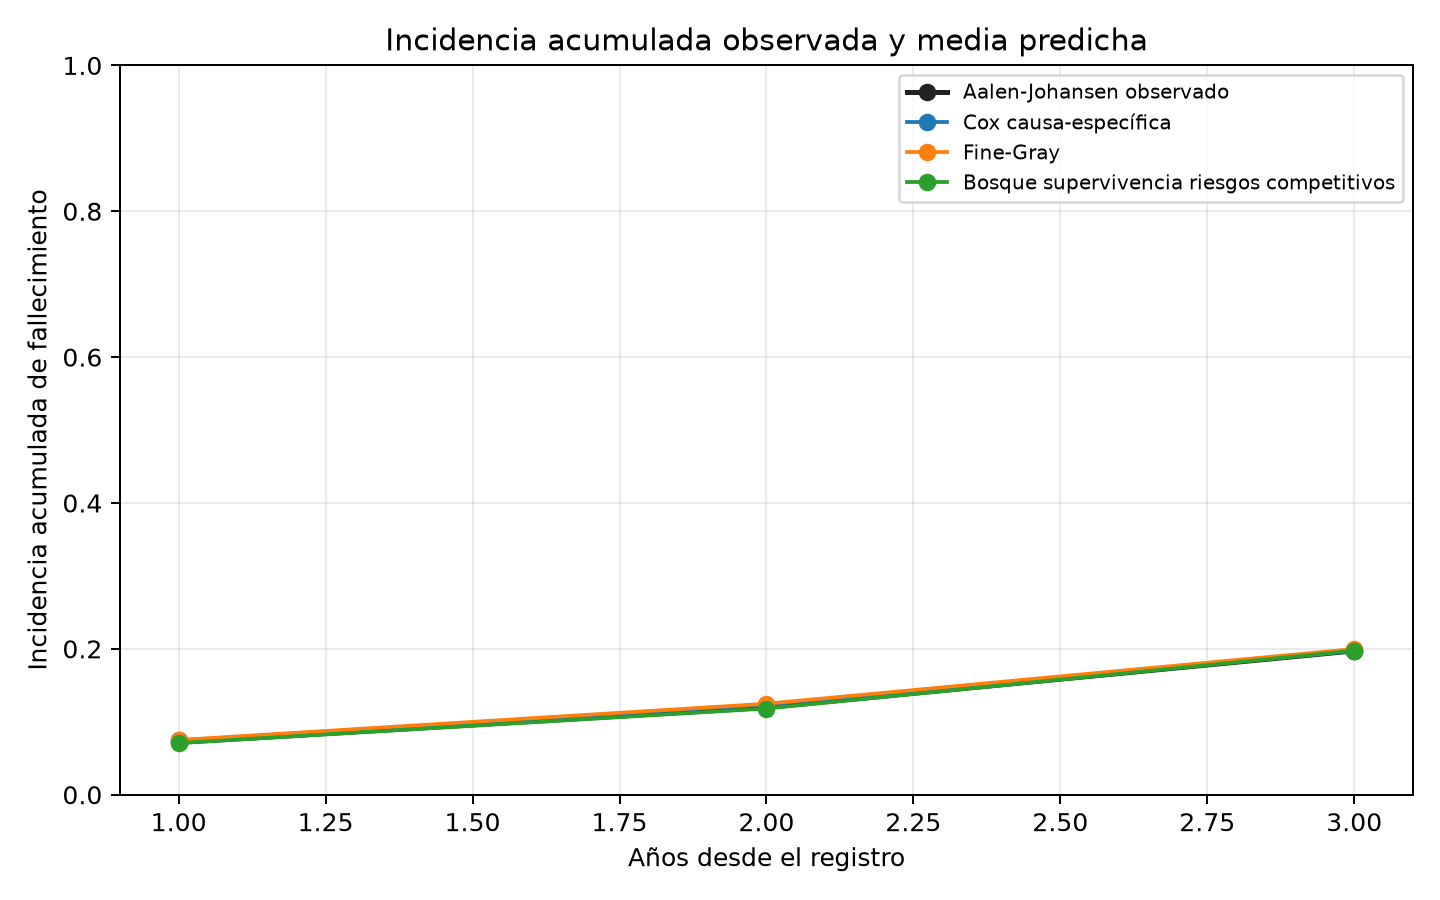

In [8]:
display(results["calibration"].head(30))
print("Figuras disponibles:")
for f in sorted(FIGURES.glob("*.png")):
    print("-", f.name)

if (FIGURES / "02_cif_observada_vs_predicha.png").exists():
    from IPython.display import Image, display as show_image
    show_image(Image(filename=str(FIGURES / "02_cif_observada_vs_predicha.png")))

## 8. Importancia de variables del bosque (exploratoria)

In [9]:
if not results["variable_importance"].empty:
    display(results["variable_importance"])
else:
    print("La importancia de variables no estuvo disponible en esta ejecución; consulte el aviso guardado en la salida de la función.")
print("Advertencia: esta importancia se calcula en un bosque ajustado con todos los datos y se interpreta como exploratoria. No se usa para estimar el rendimiento fuera de muestra.")

,feature,cause_1_vimp,cause_2_vimp,composite_vimp
0,feature_0,0.029596,0.074523,0.052059
1,feature_1,0.077507,-0.059738,0.008885
2,feature_2,0.001349,-0.030459,-0.014555
3,feature_3,0.006706,0.080694,0.043700
4,feature_4,0.001182,-0.001232,-0.000025


Advertencia: esta importancia se calcula en un bosque ajustado con todos los datos y se interpreta como exploratoria. No se usa para estimar el rendimiento fuera de muestra.


## 9. Archivos generados

Todos los resultados del análisis se guardan en `results/tables/` y `results/figures/`. Los CSV de predicciones fuera de pliegue permiten auditar y recrear las tablas del informe. No cambie el mapeo de eventos ni sustituya la censura por tiempos hipotéticos sin definir una metodología distinta.